In [33]:
import sys
from pathlib import Path

repo_root = Path.cwd()
if not (repo_root / "kine" / "obsdata.py").exists():
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root))

# NUFFT

* target: observed data Kine is tryign to reproducing (used by loss function)
* sigma: uncertainty in each observed value (used by loss function)
* uv: irreuglar Fourier coordinates where the image must be sampled (NUFFT)
* uv_indices: a map of measurements to positions in the NUFFT output
* pulse: pixel correction applied to NUFFT results
* triangles: groups of three baseline indices that form closure phases
* quadrangles: groups of four baseline indices that form closure amplitudes

Standard FFT does not work with irregular points from moving telescope baselines. NUFFT: 
1. Computes an ordinary fast FFT on a fine (oversampled) regular grid
2. Estimates Fourier value at each (u,v) point by interpolating
3. NUFFT interpolation correction handled by jax-finufft (deconvolving the interpolation kernel)
4. Image-pixel correction handled by Kine (we treat each pixel as a finite basis function, not infinitely small point, so Fourier response contributes an additional scale and phase)
    1. pulse = obs.get_pulsefac(uv, ehc.PULSE_DEFAULT)
    2. predicted_vis = nufft2(image, v, u, eps=1e-3) * pulse

In [39]:
import numpy as np
import jax.numpy as jnp
import ehtim as eh
import ehtim.const_def as ehc
import kine.obsdata as ob
import matplotlib.pyplot as plt
from jax_finufft import nufft2
from kine import utils as ut

def obsdata_to_nufft_inputs(obs, improxy):
    data = obs.unpack(["vis", "sigma"], conj=False)
    target = np.asarray(data["vis"]).reshape(1, -1)
    sigma = np.asarray(data["sigma"]).reshape(1, -1)
    baselines = obs.get_baselines_nfft()
    uv = obs.get_uvpoints(improxy.psize)
    measured_uv = obs.get_uvpoints(improxy.psize, conj=False)
    pulse = obs.get_pulsefac(uv, ehc.PULSE_DEFAULT)
    uv_indices = ut.map_val_to_ind(uv["u"][None, :], measured_uv["u"][None, :])
    triangles = obs.get_closure_indices(baselines, which="triangles")
    quadrangles = obs.get_closure_indices(baselines, which="quadrangles")
    
    return {
        "target": target,
        "sigma": sigma,
        "uv": uv,
        "uv_indices": uv_indices,
        "pulse": pulse,
        "triangles": triangles,
        "quadrangles": quadrangles,
    }


def image_to_visibilities(image, inputs):
    # Convert image to a JAX complex array (Fourier samples are complex)
    image = jnp.asarray(image, dtype=jnp.complex64)

    # Retrive irreegular Fourier coordinates that obsevations sample
    # We use (v,u) since image arrays are ordered by (row, column)
    v = jnp.asarray(inputs["uv"]["v"], dtype=jnp.float32)
    u = jnp.asarray(inputs["uv"]["u"], dtype=jnp.float32)

    # Evaluate image's Fourier transform at irregular (u, v) coordinates
    predicted_visibilities = nufft2(image, v, u, eps=1e-3)

    # Kine-specific corrections
    pulse = jnp.asarray(inputs["pulse"], dtype=jnp.complex64)
    predicted_visibilities = predicted_visibilities * pulse

    # Give back one complex predicted visibility for each (u,v)
    return predicted_visibilities

In [40]:
data_path = repo_root / "data/eht_m87_2017-04-10.uvfits"
obs = ob.Obsdata.load_uvfits(str(data_path))
# improxy = eh.image.make_square(obs, 32, 160 * eh.RADPERUAS, pol_prim="I")  # 32x32 pixel image template

Loading uvfits:  /Users/kahaan/Downloads/kine/data/eht_m87_2017-04-10.uvfits
no IF in uvfits header!
POLREP_UVFITS: circ
Number of uvfits Correlation Products: 4


In [41]:
nufft_inputs = obsdata_to_nufft_inputs(obs, improxy)
{
    "obsdata_rows": len(obs.data),
    "target": np.shape(nufft_inputs["target"]),
    "sigma": np.shape(nufft_inputs["sigma"]),
    "u": np.shape(nufft_inputs["uv"]["u"]),
    "v": np.shape(nufft_inputs["uv"]["v"]),
    "pulse": np.shape(nufft_inputs["pulse"]),
    "triangles": np.shape(nufft_inputs["triangles"]),
    "quadrangles": np.shape(nufft_inputs["quadrangles"]),
}

{'obsdata_rows': 2367,
 'target': (1, 2367),
 'sigma': (1, 2367),
 'u': (4734,),
 'v': (4734,),
 'pulse': (4734,),
 'triangles': (1526, 3),
 'quadrangles': (1340, 4)}

In [48]:
# Empty 32x32 image
candidate_image = np.zeros((32, 32), dtype=np.float32)

# Put a unit-brightness point source in the middle
candidate_image[16, 16] = 1.0

# Apply forward NUFFT (predicts what interferometer would measure)
predicted_visibilities = image_to_visibilities(candidate_image, nufft_inputs)

# Check shape of samples
predicted_visibilities.shape

(4734,)

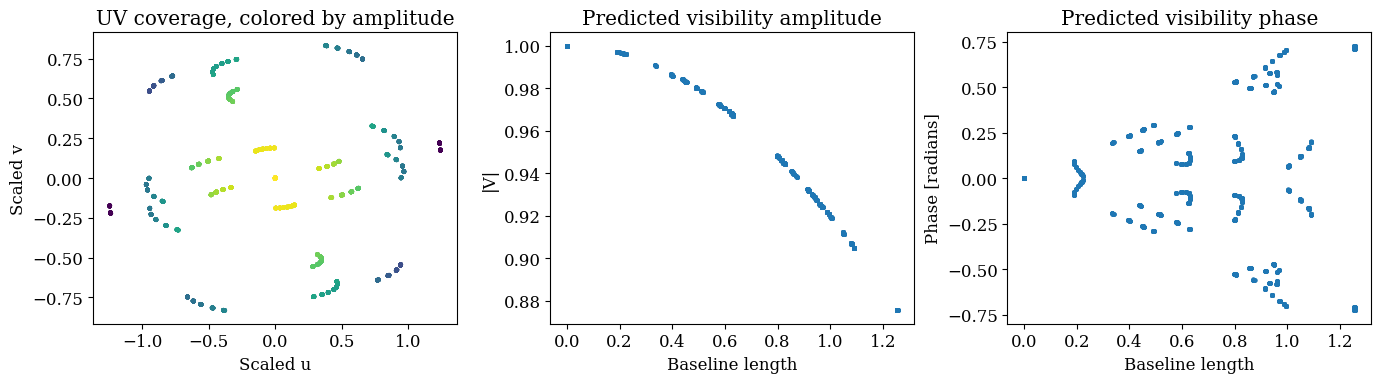

In [43]:
u = nufft_inputs["uv"]["u"]
v = nufft_inputs["uv"]["v"]
vis = np.asarray(predicted_visibilities)
baseline_length = np.sqrt(u**2 + v**2)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].scatter(u, v, c=np.abs(vis), s=5)
axes[0].set_title("UV coverage, colored by amplitude")
axes[0].set_xlabel("Scaled u")
axes[0].set_ylabel("Scaled v")

axes[1].scatter(baseline_length, np.abs(vis), s=5)
axes[1].set_title("Predicted visibility amplitude")
axes[1].set_xlabel("Baseline length")
axes[1].set_ylabel("|V|")

axes[2].scatter(baseline_length, np.angle(vis), s=5)
axes[2].set_title("Predicted visibility phase")
axes[2].set_xlabel("Baseline length")
axes[2].set_ylabel("Phase [radians]")

plt.tight_layout()

* Left: samples
* Middle: amplitude vs baseline length, how strongly the source is detected at different spatial scales, I believe ideally this is 1 everywhere
* Right: Source is centered, positive/negative pairs, symmetric (we expect ~0 phase)